# Nhiệm vụ 4: Học có giám sát – Pipeline Phân loại (Classification)

Dữ liệu: `cgv_eda_cleaned.csv`.

Các bước:
1. **Đặc trưng mục tiêu:** dự đoán nhãn phân loại rời rạc (mức nhu cầu của suất chiếu: Cao / Không cao)
2. **Thuật toán:** `LogisticRegression()` và `DecisionTreeClassifier()`
3. **Xử lý mất cân bằng:** kiểm tra phân bố nhãn, áp dụng `class_weight='balanced'` và lấy mẫu lại (oversampling)
4. **Đầu ra đánh giá:** Confusion Matrix heatmap và `classification_report` (Precision, Recall, Accuracy, F1-Score)

## 1. Đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
print("Số dòng:", len(df), "| Số cột:", len(df.columns))
df.head(3)

Số dòng: 1172 | Số cột: 18


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,70000,80,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải n...",100000,90,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,90000,80,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0


## 2. Đặc trưng mục tiêu (Target Feature)

Dữ liệu là lịch chiếu nên không có nhãn "khách hàng rời bỏ". Thay vào đó, mình phân loại **mức nhu cầu của suất chiếu** dựa trên tỉ lệ lấp đầy ghế:

`OccupancyRate = (TotalSeats − AvailableSeats) / TotalSeats`

- **Cao**: tỉ lệ lấp đầy lớn hơn mức trung vị (20%)
- **Không cao**: tỉ lệ lấp đầy từ mức trung vị trở xuống

Đây là bài toán phân loại nhị phân, phục vụ câu hỏi thực tế: *suất chiếu nào có khả năng đông khách hơn bình thường?*

In [2]:
df["OccupancyRate"] = (df["TotalSeats"] - df["AvailableSeats"]) / df["TotalSeats"]

threshold = df["OccupancyRate"].median()
print(f"Ngưỡng (trung vị tỉ lệ lấp đầy): {threshold:.1%}")

df["DemandLevel"] = np.where(df["OccupancyRate"] > threshold, "Cao", "Không cao")
y = df["DemandLevel"]

print("\nSố lượng từng nhãn:")
print(y.value_counts())
print("\nTỉ lệ từng nhãn:")
print(y.value_counts(normalize=True).round(3))

Ngưỡng (trung vị tỉ lệ lấp đầy): 20.0%

Số lượng từng nhãn:
DemandLevel
Không cao    844
Cao          328
Name: count, dtype: int64

Tỉ lệ từng nhãn:
DemandLevel
Không cao    0.72
Cao          0.28
Name: proportion, dtype: float64


### 2.1. Kiểm tra tình trạng mất cân bằng nhãn

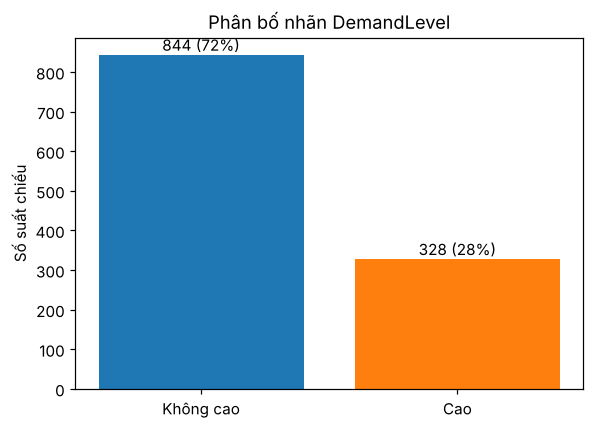

Tỉ lệ lớp đa số / lớp thiểu số: 2.57:1
=> Nhãn mất cân bằng (lớp 'Cao' ít hơn); accuracy một mình sẽ gây hiểu lầm, cần xem Recall/F1 của lớp 'Cao'.


In [3]:
counts = y.value_counts()
fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(counts.index, counts.values, color=["#1f77b4", "#ff7f0e"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 10, f"{v} ({v/len(y):.0%})", ha="center")
ax.set_title("Phân bố nhãn DemandLevel")
ax.set_ylabel("Số suất chiếu")
plt.tight_layout()
plt.show()

ratio = counts.max() / counts.min()
print(f"Tỉ lệ lớp đa số / lớp thiểu số: {ratio:.2f}:1")
print("=> Nhãn mất cân bằng (lớp 'Cao' ít hơn); accuracy một mình sẽ gây hiểu lầm, cần xem Recall/F1 của lớp 'Cao'.")

## 3. Chuẩn bị đặc trưng đầu vào (X)

- Số: `DurationMinutes`, `ShowHour`, `DaysSinceRelease`, `IsWeekend`, `IsPremiumRoom`, `TotalSeats`, `TicketPrice`
- Biến phân loại → số: one-hot `Cinema`, `Rating`, loại định dạng chiếu (`FormatTech`); multi-hot `Genre`

**Tránh rò rỉ dữ liệu:** loại `AvailableSeats` (và mọi cột suy ra từ nó) khỏi X vì nhãn được tính trực tiếp từ cột này.

In [4]:
feat = pd.DataFrame(index=df.index)

feat["DurationMinutes"] = pd.to_numeric(df["DurationMinutes"], errors="coerce")
t = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce")
feat["ShowHour"] = t.dt.hour + t.dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)
feat["TotalSeats"] = pd.to_numeric(df["TotalSeats"], errors="coerce")
feat["TicketPrice"] = pd.to_numeric(df["TicketPrice"], errors="coerce")

cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X = pd.concat([feat, cat_dummies, genre_dummies], axis=1)

print("Kích thước X:", X.shape)
print("Giá trị thiếu trong X:", int(X.isna().sum().sum()))
X.head(3)

Kích thước X: (1172, 31)
Giá trị thiếu trong X: 0


,DurationMinutes,ShowHour,DaysSinceRelease,IsWeekend,IsPremiumRoom,TotalSeats,TicketPrice,Cinema_CGV Crescent Mall,Cinema_CGV Hùng Vương Plaza,Cinema_CGV Thảo Điền Pearl,...,Genre_Gia đình,Genre_Hoạt Hình,Genre_Hài,Genre_Hành Động,Genre_Hồi hộp,Genre_Khoa Học Viễn Tưởng,Genre_Kinh Dị,Genre_Phiêu Lưu,Genre_Thần thoại,Genre_Tâm Lý
0,183.0,10.5,6,0,1,100,70000,1,0,0,...,0,0,0,1,0,1,0,1,0,0
1,183.0,16.0,6,0,1,100,100000,1,0,0,...,0,0,0,1,0,1,0,1,0,0
2,183.0,21.5,6,0,1,100,90000,1,0,0,...,0,0,0,1,0,1,0,1,0,0


## 4. Chia tập Train / Test (có phân tầng)

Dùng `stratify=y` để giữ nguyên tỉ lệ nhãn ở cả hai tập, điều quan trọng khi dữ liệu mất cân bằng.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Tỉ lệ 'Cao' - train:", round((y_train == "Cao").mean(), 3), "| test:", round((y_test == "Cao").mean(), 3))

Train: (937, 31) | Test: (235, 31)
Tỉ lệ 'Cao' - train: 0.28 | test: 0.281


## 5. Huấn luyện và so sánh: có và không xử lý mất cân bằng

Với mỗi thuật toán (`LogisticRegression`, `DecisionTreeClassifier`) thử 3 cách:
1. **Không xử lý** mất cân bằng
2. **`class_weight='balanced'`**: tăng trọng số lỗi cho lớp thiểu số
3. **Random oversampling**: nhân bản ngẫu nhiên mẫu lớp thiểu số trong tập train (chỉ trên train để không rò rỉ sang test)

Cây quyết định được giới hạn độ sâu (`max_depth=4`, `min_samples_leaf=20`) để tránh overfit; bước tinh chỉnh bằng `GridSearchCV` ở mục 7.

In [6]:
# Random oversampling trên tập train
train_df = X_train.copy()
train_df["__y__"] = y_train.values
major = train_df[train_df["__y__"] == "Không cao"]
minor = train_df[train_df["__y__"] == "Cao"]
minor_up = resample(minor, replace=True, n_samples=len(major), random_state=RANDOM_STATE)
train_os = pd.concat([major, minor_up]).sample(frac=1, random_state=RANDOM_STATE)
X_train_os = train_os.drop(columns="__y__")
y_train_os = train_os["__y__"]
print("Sau oversampling:", y_train_os.value_counts().to_dict())

Sau oversampling: {'Không cao': 675, 'Cao': 675}


In [7]:
def make_model(kind, balanced):
    cw = "balanced" if balanced else None
    if kind == "LogisticRegression":
        return make_pipeline(StandardScaler(),
                             LogisticRegression(class_weight=cw, max_iter=2000, random_state=RANDOM_STATE))
    return DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                  class_weight=cw, random_state=RANDOM_STATE)

experiments = {}   # (tên mô hình, cách xử lý) -> mô hình đã huấn luyện
for kind in ["LogisticRegression", "DecisionTreeClassifier"]:
    experiments[(kind, "Không xử lý")] = make_model(kind, False).fit(X_train, y_train)
    experiments[(kind, "class_weight='balanced'")] = make_model(kind, True).fit(X_train, y_train)
    experiments[(kind, "Random oversampling")] = make_model(kind, False).fit(X_train_os, y_train_os)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print("Đã huấn luyện", len(experiments), "mô hình + 1 mô hình cơ sở")

Đã huấn luyện 6 mô hình + 1 mô hình cơ sở


## 6. Đánh giá trên tập test

Lớp quan tâm (positive) là **'Cao'**.

In [8]:
POS = "Cao"

def metrics(model, Xa, ya):
    pred = model.predict(Xa)
    proba = model.predict_proba(Xa)[:, list(model.classes_).index(POS)]
    return {
        "Accuracy": accuracy_score(ya, pred),
        "Precision (Cao)": precision_score(ya, pred, pos_label=POS, zero_division=0),
        "Recall (Cao)": recall_score(ya, pred, pos_label=POS, zero_division=0),
        "F1 (Cao)": f1_score(ya, pred, pos_label=POS, zero_division=0),
        "F1 macro": f1_score(ya, pred, average="macro"),
        "ROC-AUC": roc_auc_score((ya == POS).astype(int), proba),
    }

rows = {"Cơ sở (luôn đoán lớp đa số)": metrics(baseline, X_test, y_test)}
for (kind, how), mdl in experiments.items():
    rows[f"{kind} | {how}"] = metrics(mdl, X_test, y_test)

results = pd.DataFrame(rows).T
pd.options.display.float_format = "{:.3f}".format
display(results)

,Accuracy,Precision (Cao),Recall (Cao),F1 (Cao),F1 macro,ROC-AUC
Cơ sở (luôn đoán lớp đa số),0.719,0.000,0.000,0.000,0.418,0.500
LogisticRegression | Không xử lý,0.732,0.714,0.076,0.137,0.489,0.555
LogisticRegression | class_weight='balanced',0.549,0.315,0.515,0.391,0.516,0.560
LogisticRegression | Random oversampling,0.545,0.305,0.485,0.374,0.508,0.561
DecisionTreeClassifier | Không xử lý,0.745,0.650,0.197,0.302,0.573,0.596
DecisionTreeClassifier | class_weight='balanced',0.774,0.741,0.303,0.430,0.645,0.596
DecisionTreeClassifier | Random oversampling,0.774,0.741,0.303,0.430,0.645,0.598


**Cách đọc bảng:**
- Mô hình cơ sở luôn đoán lớp đa số nên có Accuracy cao nhưng **Recall (Cao) = 0**, không phát hiện được suất chiếu đông khách nào.
- Khi xử lý mất cân bằng, Recall và F1 của lớp "Cao" tăng, đổi lại Accuracy có thể giảm: đây là đánh đổi cần có.
- **F1 macro** và **F1 (Cao)** là thước đo phù hợp hơn Accuracy cho dữ liệu mất cân bằng.

## 7. Tinh chỉnh cây quyết định (`GridSearchCV`)

Tìm `max_depth` và `min_samples_leaf` tốt nhất bằng kiểm tra chéo 5-fold phân tầng trên tập train, tối ưu **F1 macro**, kết hợp `class_weight='balanced'`.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid={"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 40]},
    scoring="f1_macro", cv=cv,
).fit(X_train, y_train)

tree_tuned = grid.best_estimator_
print("Tham số tốt nhất:", grid.best_params_)
print(f"F1 macro (CV, train): {grid.best_score_:.3f}")

logit_bal = experiments[("LogisticRegression", "class_weight='balanced'")]

final_models = {
    "LogisticRegression (balanced)": logit_bal,
    "DecisionTree (tinh chỉnh, balanced)": tree_tuned,
}
final_results = pd.DataFrame({n: metrics(mdl, X_test, y_test) for n, mdl in final_models.items()}).T
display(final_results)

# Kiểm tra ổn định bằng cross-validation trên toàn bộ dữ liệu
for n, mdl in final_models.items():
    s = cross_val_score(mdl, X, y, cv=cv, scoring="f1_macro")
    print(f"{n}: F1 macro CV = {s.mean():.3f} ± {s.std():.3f}")
dummy_cv = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv, scoring="f1_macro")
print(f"Cơ sở (lớp đa số): F1 macro CV = {dummy_cv.mean():.3f}")

Tham số tốt nhất: {'max_depth': 2, 'min_samples_leaf': 10}
F1 macro (CV, train): 0.649


,Accuracy,Precision (Cao),Recall (Cao),F1 (Cao),F1 macro,ROC-AUC
LogisticRegression (balanced),0.549,0.315,0.515,0.391,0.516,0.560
"DecisionTree (tinh chỉnh, balanced)",0.774,0.741,0.303,0.430,0.645,0.629


LogisticRegression (balanced): F1 macro CV = 0.496 ± 0.031
DecisionTree (tinh chỉnh, balanced): F1 macro CV = 0.647 ± 0.041
Cơ sở (lớp đa số): F1 macro CV = 0.419


## 8. Ma trận nhầm lẫn (Confusion Matrix heatmap)

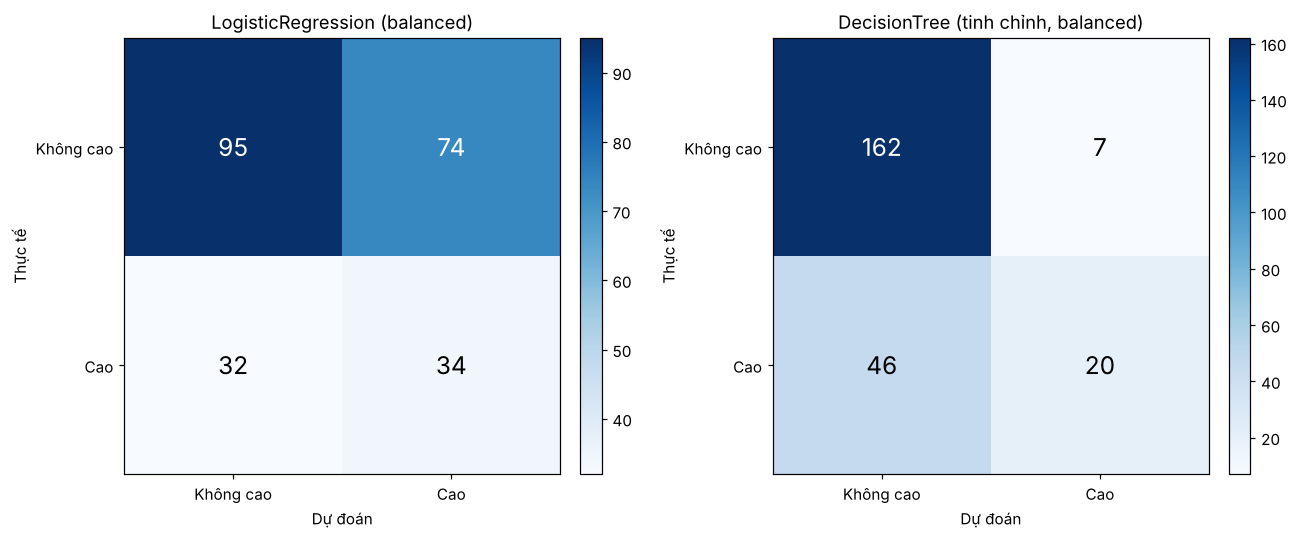

In [10]:
labels = ["Không cao", "Cao"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, mdl) in zip(axes, final_models.items()):
    pred = mdl.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=labels)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(2)); ax.set_xticklabels(labels)
    ax.set_yticks(range(2)); ax.set_yticklabels(labels)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    ax.set_title(name)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 9. Báo cáo phân loại chi tiết (`classification_report`)

In [11]:
for name, mdl in final_models.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, mdl.predict(X_test), digits=3))

LogisticRegression (balanced)
              precision    recall  f1-score   support

         Cao      0.315     0.515     0.391        66
   Không cao      0.748     0.562     0.642       169

    accuracy                          0.549       235
   macro avg      0.531     0.539     0.516       235
weighted avg      0.626     0.549     0.571       235

DecisionTree (tinh chỉnh, balanced)
              precision    recall  f1-score   support

         Cao      0.741     0.303     0.430        66
   Không cao      0.779     0.959     0.859       169

    accuracy                          0.774       235
   macro avg      0.760     0.631     0.645       235
weighted avg      0.768     0.774     0.739       235



## 10. Đặc trưng nào ảnh hưởng nhiều nhất?

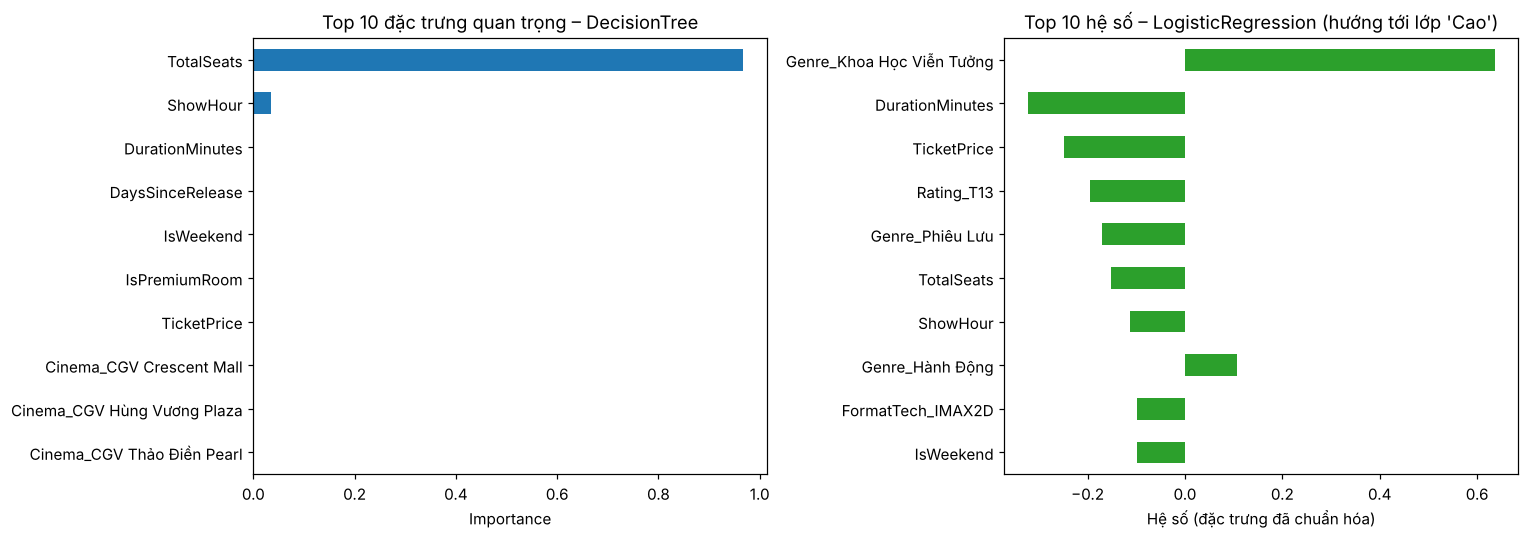

In [12]:
importances = pd.Series(tree_tuned.feature_importances_, index=X.columns).sort_values(ascending=False)
coef = pd.Series(logit_bal.named_steps["logisticregression"].coef_[0], index=X.columns)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
importances.head(10)[::-1].plot(kind="barh", ax=axes[0], color="#1f77b4")
axes[0].set_title("Top 10 đặc trưng quan trọng – DecisionTree")
axes[0].set_xlabel("Importance")

top_coef[::-1].plot(kind="barh", ax=axes[1], color="#2ca02c")
axes[1].set_title("Top 10 hệ số – LogisticRegression (hướng tới lớp 'Cao')")
axes[1].set_xlabel("Hệ số (đặc trưng đã chuẩn hóa)")
plt.tight_layout()
plt.show()

## 11. Kết luận

- **Biến mục tiêu:** `DemandLevel` (Cao / Không cao) theo tỉ lệ lấp đầy ghế so với mức trung vị 20%. Nhãn mất cân bằng nhẹ (khoảng 72% / 28%).
- **Xử lý mất cân bằng:** thử không xử lý, `class_weight='balanced'` và random oversampling. Mô hình không xử lý có Accuracy khá nhưng gần như bỏ sót lớp "Cao" (Recall rất thấp); hai cách xử lý đều cải thiện F1 macro.
- **So sánh thuật toán:** `DecisionTreeClassifier` tinh chỉnh (balanced) cho F1 macro khoảng 0,65 trên cả tập test và kiểm tra chéo, cao hơn `LogisticRegression` (khoảng 0,50) và mô hình cơ sở luôn đoán lớp đa số (khoảng 0,42). `LogisticRegression` balanced bắt được nhiều suất "Cao" hơn (Recall 0,52) nhưng nhầm nhiều (Precision 0,32).
- **Đọc kết quả thận trọng:** cây tối ưu chỉ sâu 2 tầng và chủ yếu tách theo `TotalSeats`. Phòng 80 và 120 ghế có tỉ lệ "Cao" lớn hơn nhiều so với phòng 100 ghế, một phần vì số vé bán ra tập trung ở các mức rời rạc (10, 20, 30 vé) nên phòng nhỏ có tỉ lệ lấp đầy cao hơn. Vì vậy mô hình học chủ yếu quy luật này, các đặc trưng như phim, rạp, giờ chiếu đóng góp rất ít.
- **Hạn chế:** dữ liệu lịch chiếu không có nhãn khách hàng thật (như rời bỏ/đang hoạt động) và ít tín hiệu về nhu cầu, nên hiệu năng ở mức khiêm tốn. Để cải thiện cần dữ liệu số vé bán thực tế theo thời gian, khuyến mãi, hoặc mức độ phổ biến của phim.